# Assignment 14: Support Vector Machine (SVM) – Parkinson's Disease Classification

In this assignment I build a Support Vector Machine (SVM) classifier to predict whether a person has Parkinson's disease, using the Parkinson's Disease dataset provided for this course.

SVM finds the boundary (hyperplane) that separates the two classes with the widest possible margin. It is sensitive to feature scales, so scaling is an important part of the process.

Steps I will follow:
1. Import libraries and load the data
2. Check the structure and remove duplicates
3. Split the data into training and testing sets
4. Explore the training data (EDA)
5. Preprocess: handle missing values, separate features and target, scale features
6. Build and train SVM models (linear and RBF kernels)
7. Evaluate with a classification report and a confusion matrix heatmap
8. Tune hyperparameters with GridSearchCV
9. Write a short report on performance and challenges

## Step 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, GroupShuffleSplit, StratifiedKFold,
                                     StratifiedGroupKFold, GridSearchCV, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix, RocCurveDisplay)

pd.set_option("display.max_columns", None)

## Step 2: Load the Dataset and Check Its Structure

In [2]:
file_name = "Parkinson disease.csv"
park = pd.read_csv(file_name)

In [3]:
print("Shape:", park.shape)
display(park.head())
park.info()

Shape: (756, 755)


,id,gender,PPE,EEG,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter,locAbsJitter,rapJitter,ppq5Jitter,ddpJitter,locShimmer,locDbShimmer,apq3Shimmer,apq5Shimmer,apq11Shimmer,ddaShimmer,meanAutoCorrHarmonicity,meanNoiseToHarmHarmonicity,meanHarmToNoiseHarmonicity,minIntensity,maxIntensity,meanIntensity,f1,f2,f3,f4,b1,b2,b3,b4,GQ_prc5_95,GQ_std_cycle_open,GQ_std_cycle_closed,GNE_mean,GNE_std,GNE_SNR_TKEO,GNE_SNR_SEO,GNE_NSR_TKEO,GNE_NSR_SEO,VFER_mean,VFER_std,VFER_entropy,VFER_SNR_TKEO,VFER_SNR_SEO,VFER_NSR_TKEO,VFER_NSR_SEO,IMF_SNR_SEO,IMF_SNR_TKEO,IMF_SNR_entropy,IMF_NSR_SEO,IMF_NSR_TKEO,IMF_NSR_entropy,mean_Log_energy,mean_MFCC_0th_coef,mean_MFCC_1st_coef,mean_MFCC_2nd_coef,mean_MFCC_3rd_coef,mean_MFCC_4th_coef,mean_MFCC_5th_coef,mean_MFCC_6th_coef,mean_MFCC_7th_coef,mean_MFCC_8th_coef,mean_MFCC_9th_coef,mean_MFCC_10th_coef,mean_MFCC_11th_coef,mean_MFCC_12th_coef,mean_delta_log_energy,mean_0th_delta,mean_1st_delta,mean_2nd_delta,mean_3rd_delta,mean_4th_delta,mean_5th_delta,mean_6th_delta,mean_7th_delta,mean_8th_delta,mean_9th_delta,mean_10th_delta,mean_11th_delta,mean_12th_delta,mean_delta_delta_log_energy,mean_delta_delta_0th,mean_1st_delta_delta,mean_2nd_delta_delta,mean_3rd_delta_delta,mean_4th_delta_delta,mean_5th_delta_delta,mean_6th_delta_delta,mean_7th_delta_delta,mean_8th_delta_delta,mean_9th_delta_delta,mean_10th_delta_delta,mean_11th_delta_delta,mean_12th_delta_delta,std_Log_energy,std_MFCC_0th_coef,std_MFCC_1st_coef,std_MFCC_2nd_coef,std_MFCC_3rd_coef,std_MFCC_4th_coef,std_MFCC_5th_coef,std_MFCC_6th_coef,std_MFCC_7th_coef,std_MFCC_8th_coef,std_MFCC_9th_coef,std_MFCC_10th_coef,std_MFCC_11th_coef,std_MFCC_12th_coef,std_delta_log_energy,std_0th_delta,std_1st_delta,std_2nd_delta,std_3rd_delta,std_4th_delta,std_5th_delta,std_6th_delta,std_7th_delta,std_8th_delta,std_9th_delta,std_10th_delta,std_11th_delta,std_12th_delta,std_delta_delta_log_energy,std_delta_delta_0th,std_1st_delta_delta,std_2nd_delta_delta,std_3rd_delta_delta,std_4th_delta_delta,std_5th_delta_delta,std_6th_delta_delta,std_7th_delta_delta,std_8th_delta_delta,std_9th_delta_delta,std_10th_delta_delta,std_11th_delta_delta,std_12th_delta_delta,Ea,Ed_1_coef,Ed_2_coef,Ed_3_coef,Ed_4_coef,Ed_5_coef,Ed_6_coef,Ed_7_coef,Ed_8_coef,Ed_9_coef,Ed_10_coef,det_entropy_shannon_1_coef,det_entropy_shannon_2_coef,det_entropy_shannon_3_coef,det_entropy_shannon_4_coef,det_entropy_shannon_5_coef,det_entropy_shannon_6_coef,det_entropy_shannon_7_coef,det_entropy_shannon_8_coef,det_entropy_shannon_9_coef,det_entropy_shannon_10_coef,det_entropy_log_1_coef,det_entropy_log_2_coef,det_entropy_log_3_coef,det_entropy_log_4_coef,det_entropy_log_5_coef,det_entropy_log_6_coef,det_entropy_log_7_coef,det_entropy_log_8_coef,det_entropy_log_9_coef,det_entropy_log_10_coef,det_TKEO_mean_1_coef,det_TKEO_mean_2_coef,det_TKEO_mean_3_coef,det_TKEO_mean_4_coef,det_TKEO_mean_5_coef,det_TKEO_mean_6_coef,det_TKEO_mean_7_coef,det_TKEO_mean_8_coef,det_TKEO_mean_9_coef,det_TKEO_mean_10_coef,det_TKEO_std_1_coef,det_TKEO_std_2_coef,det_TKEO_std_3_coef,det_TKEO_std_4_coef,det_TKEO_std_5_coef,det_TKEO_std_6_coef,det_TKEO_std_7_coef,det_TKEO_std_8_coef,det_TKEO_std_9_coef,det_TKEO_std_10_coef,app_entropy_shannon_1_coef,app_entropy_shannon_2_coef,app_entropy_shannon_3_coef,app_entropy_shannon_4_coef,app_entropy_shannon_5_coef,app_entropy_shannon_6_coef,app_entropy_shannon_7_coef,app_entropy_shannon_8_coef,app_entropy_shannon_9_coef,app_entropy_shannon_10_coef,app_entropy_log_1_coef,app_entropy_log_2_coef,app_entropy_log_3_coef,app_entropy_log_4_coef,app_entropy_log_5_coef,app_entropy_log_6_coef,app_entropy_log_7_coef,app_entropy_log_8_coef,app_entropy_log_9_coef,app_entropy_log_10_coef,app_det_TKEO_mean_1_coef,app_det_TKEO_mean_2_coef,app_det_TKEO_mean_3_coef,app_det_TKEO_mean_4_coef,app_det_TKEO_mean_5_coef,app_det_TKEO_mean_6_coef,app_det_TKEO_mean_7_coef,app_det_TKEO_mean_8_coef,app_det_TKEO_mean_9_coef,app_det_TKEO_mean_10_coef,app_TKEO_std_1_coef,app_TKEO_std_2_coef,app_TKEO_

<class 'pandas.DataFrame'>
RangeIndex: 756 entries, 0 to 755
Columns: 755 entries, id to class
dtypes: float64(749), int64(6)
memory usage: 4.4 MB


In [4]:
print("\nMissing values per column:\n", park.isnull().sum()[park.isnull().sum() > 0])


Missing values per column:
 Series([], dtype: int64)


In [5]:
print("Total missing:", park.isnull().sum().sum())

Total missing: 0


In [6]:
print("Duplicate rows:", park.duplicated().sum())

Duplicate rows: 1


In [7]:
# How many people, and how many recordings per person?
print("\nUnique people (id):", park["id"].nunique())
print("Recordings per person:\n", park.groupby("id").size().value_counts())


Unique people (id): 252
Recordings per person:
 3    252
Name: count, dtype: int64


In [8]:
# Does each person always have the same class?
print("Same class for all recordings of a person:", (park.groupby("id")["class"].nunique() == 1).all())


Same class for all recordings of a person: True


In [9]:
# Number of features vs number of people
print("Number of features (without id and class):", park.shape[1] - 2)
print("\nClass counts (recordings):\n", park["class"].value_counts())

Number of features (without id and class): 753

Class counts (recordings):
 class
1    564
0    192
Name: count, dtype: int64


### Interpretation: Dataset Structure

The dataset has 756 rows and 755 columns. Each row is one voice recording. The columns are:
- id: the person's ID. There are 252 people, and each person was recorded 3 times.
- gender: 0 or 1.
- 753 voice measurement features, such as jitter and shimmer (small changes in pitch and loudness), PPE (pitch period entropy), harmonicity, MFCCs (Mel-Frequency Cepstral Coefficients) and wavelet / TQWT (Tunable Q-factor Wavelet Transform) features.
- class: the target. 1 = Parkinson's disease, 0 = healthy.

All columns are numeric (749 float and 6 integer), so no encoding is needed. There are no missing values. There is 1 duplicate row, which I will remove before splitting.

Two things stand out:
1. Each person appears 3 times. If I split randomly, recordings from the same person could end up in both the training and test sets. The model could then "recognize" the person's voice instead of learning signs of Parkinson's, which would make the test score look better than it really is. To avoid this, I will split by person.
2. There are 753 features but only 252 people. This is high-dimensional data, where SVM usually performs well, but feature scaling will be very important.

## Step 3: Remove Duplicates and Split the Data by Person

In [10]:
park = park.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", park.shape)

X = park.drop(columns=["id", "class"])
y = park["class"]
groups = park["id"]

Shape after removing duplicates: (755, 755)


In [11]:
# 5 stratified folds that keep each person in one fold; use the first fold as the 20% test set
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("People in train:", groups_train.nunique(), "| People in test:", groups.iloc[test_idx].nunique())
print("People in BOTH sets:", len(set(groups_train) & set(groups.iloc[test_idx])))
print("\nClass proportions (train):", y_train.value_counts(normalize=True).round(3).to_dict())
print("Class proportions (test): ", y_test.value_counts(normalize=True).round(3).to_dict())

Train: (602, 753) | Test: (153, 753)
People in train: 201 | People in test: 51
People in BOTH sets: 0

Class proportions (train): {1: 0.746, 0: 0.254}
Class proportions (test):  {1: 0.745, 0: 0.255}


### Interpretation: Removing Duplicates and Splitting by Person

After removing the 1 duplicate row, the dataset has 755 recordings.

I split the data by person using StratifiedGroupKFold, so that all recordings of the same person go to either the training set or the test set, never both. I used the first of 5 folds as the test set, which gives about an 80/20 split:
- Training set: 602 recordings from 201 people
- Test set: 153 recordings from 51 people

The check shows 0 people appear in both sets, so there is no data leakage between training and testing. The model will be tested on voices it has never heard before, which is how it would be used in real life with new patients.

The class proportions are almost identical in both sets: about 74.6% Parkinson's and 25.4% healthy in training, and 74.5% / 25.5% in testing. This means the stratification worked.

## Step 4: Exploratory Data Analysis (Training Data Only) – Target, Gender, Feature Scales and Skewness

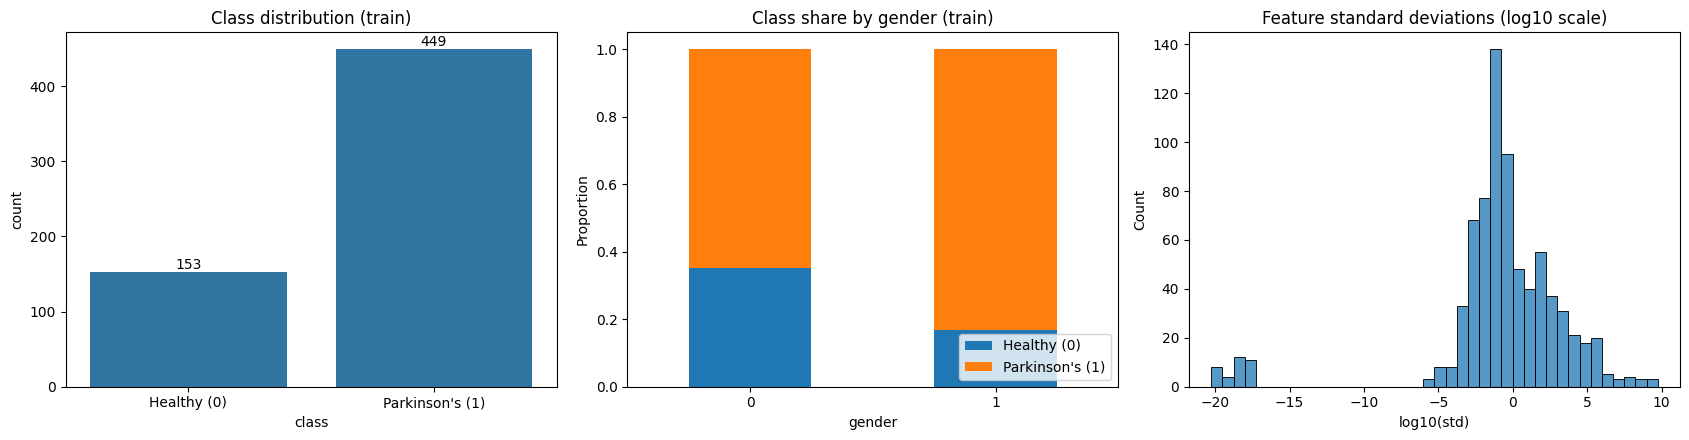

In [12]:
train_df = X_train.copy()
train_df["class"] = y_train.values

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# 1. Target distribution
sns.countplot(x="class", data=train_df, ax=axes[0])
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["Healthy (0)", "Parkinson's (1)"])
axes[0].set_title("Class distribution (train)")
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")

# 2. Gender vs class
pd.crosstab(train_df["gender"], train_df["class"], normalize="index").plot(kind="bar", stacked=True, ax=axes[1], rot=0)
axes[1].set_title("Class share by gender (train)"); axes[1].set_ylabel("Proportion")
axes[1].legend(["Healthy (0)", "Parkinson's (1)"], loc="lower right")

# 3. Feature scales: spread of standard deviations (log scale)
desc = X_train.describe().T
sns.histplot(np.log10(desc["std"]), bins=40, ax=axes[2])
axes[2].set_title("Feature standard deviations (log10 scale)"); axes[2].set_xlabel("log10(std)")
plt.tight_layout(); plt.show()

In [13]:
print("Gender vs class (row %):\n", pd.crosstab(train_df["gender"], train_df["class"], normalize="index").round(3))

print("\nSmallest std:", desc["std"].min(), "| Largest std:", desc["std"].max())
print("\n3 features with the SMALLEST spread:")
print(desc.sort_values("std")[["mean", "std", "min", "max"]].head(3))
print("\n3 features with the LARGEST spread:")
print(desc.sort_values("std")[["mean", "std", "min", "max"]].tail(3))

skew = X_train.skew()
print("\nFeatures with |skew| > 1:", (skew.abs() > 1).sum(), "out of", X_train.shape[1])
print("Top 5 most skewed:\n", skew.abs().sort_values(ascending=False).head(5).round(1))


Gender vs class (row %):
 class       0      1
gender              
0       0.352  0.648
1       0.168  0.832

Smallest std: 5.503490317228687e-21 | Largest std: 5494800810.031701

3 features with the SMALLEST spread:
                              mean           std           min           max
tqwt_meanValue_dec_2 -5.037705e-23  5.503490e-21 -3.270000e-20  4.300000e-20
tqwt_meanValue_dec_1 -4.979373e-22  6.450952e-21 -3.610000e-20  3.450000e-20
tqwt_meanValue_dec_3 -2.540137e-22  7.219723e-21 -8.110000e-20  2.630000e-20

3 features with the LARGEST spread:
                                     mean           std           min  \
app_entropy_shannon_8_coef  -2.040586e+09  1.271626e+09 -1.439981e+10   
app_entropy_shannon_9_coef  -4.256676e+09  2.645290e+09 -2.991874e+10   
app_entropy_shannon_10_coef -8.862382e+09  5.494801e+09 -6.206224e+10   

                                      max  
app_entropy_shannon_8_coef  -3.242897e+08  
app_entropy_shannon_9_coef  -6.791068e+08  
app_entropy_

### Interpretation: EDA Part 1 – Target, Gender, Feature Scales and Skewness

Target:
The training set has 449 Parkinson's recordings and 153 healthy recordings, about 75% / 25%. The data is imbalanced, so accuracy alone can be misleading. A model that always predicts "Parkinson's" would already get about 75% accuracy. I will focus on precision, recall and F1 for both classes, and try class weights during tuning.

Gender:
In gender group 0, 35.2% of recordings are healthy and 64.8% have Parkinson's. In gender group 1, only 16.8% are healthy and 83.2% have Parkinson's. So gender is related to the diagnosis and is a useful feature.

Feature scales:
The standard deviations of the features range from about 0.0000000000000000000055 (10 to the power of -21) to about 5.5 billion. That is a difference of around 30 orders of magnitude. The largest features are the app_entropy_shannon coefficients, with values in the billions. SVM is based on distances, so without scaling these large features would completely dominate the model. This confirms that I must scale the features.

The histogram also shows a small group of features with a standard deviation around 10 to the power of -20, such as tqwt_meanValue_dec_1 to dec_3. Their values are practically zero, which looks like rounding noise rather than real information. If I standardize them, the scaler would blow this noise up to the same size as the real features, so I will remove near-constant features during cleaning.

Skewness:
541 of the 753 features are strongly skewed (absolute skewness above 1), and the most skewed TQWT features have a skewness of about 23. Many features also contain negative values, so a log transform is not possible for all of them. I will rely on StandardScaler instead. SVM does not assume that features are normally distributed, but it does need them to be on similar scales.

## Step 5: Exploratory Data Analysis (Training Data Only) – Correlations and Key Features

In [14]:
# 1. Multicollinearity: how many feature pairs are highly correlated?
corr = X_train.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
print("Feature pairs with |correlation| > 0.9:", int((upper > 0.9).sum().sum()))
print("Features involved in at least one such pair:", int((upper > 0.9).any().sum()), "out of", X_train.shape[1])

Feature pairs with |correlation| > 0.9: 1917
Features involved in at least one such pair: 368 out of 753


In [15]:
# 2. Which features are most related to the target?
target_corr = X_train.corrwith(y_train).sort_values(key=abs, ascending=False)
print("\nTop 10 features most correlated with class:")
print(target_corr.head(10).round(3))


Top 10 features most correlated with class:
mean_MFCC_2nd_coef      0.387
std_9th_delta_delta     0.376
std_10th_delta_delta    0.366
tqwt_stdValue_dec_11   -0.364
std_8th_delta_delta     0.364
tqwt_minValue_dec_12    0.363
tqwt_maxValue_dec_11   -0.363
std_7th_delta_delta     0.358
tqwt_maxValue_dec_12   -0.358
std_6th_delta_delta     0.357
dtype: float64


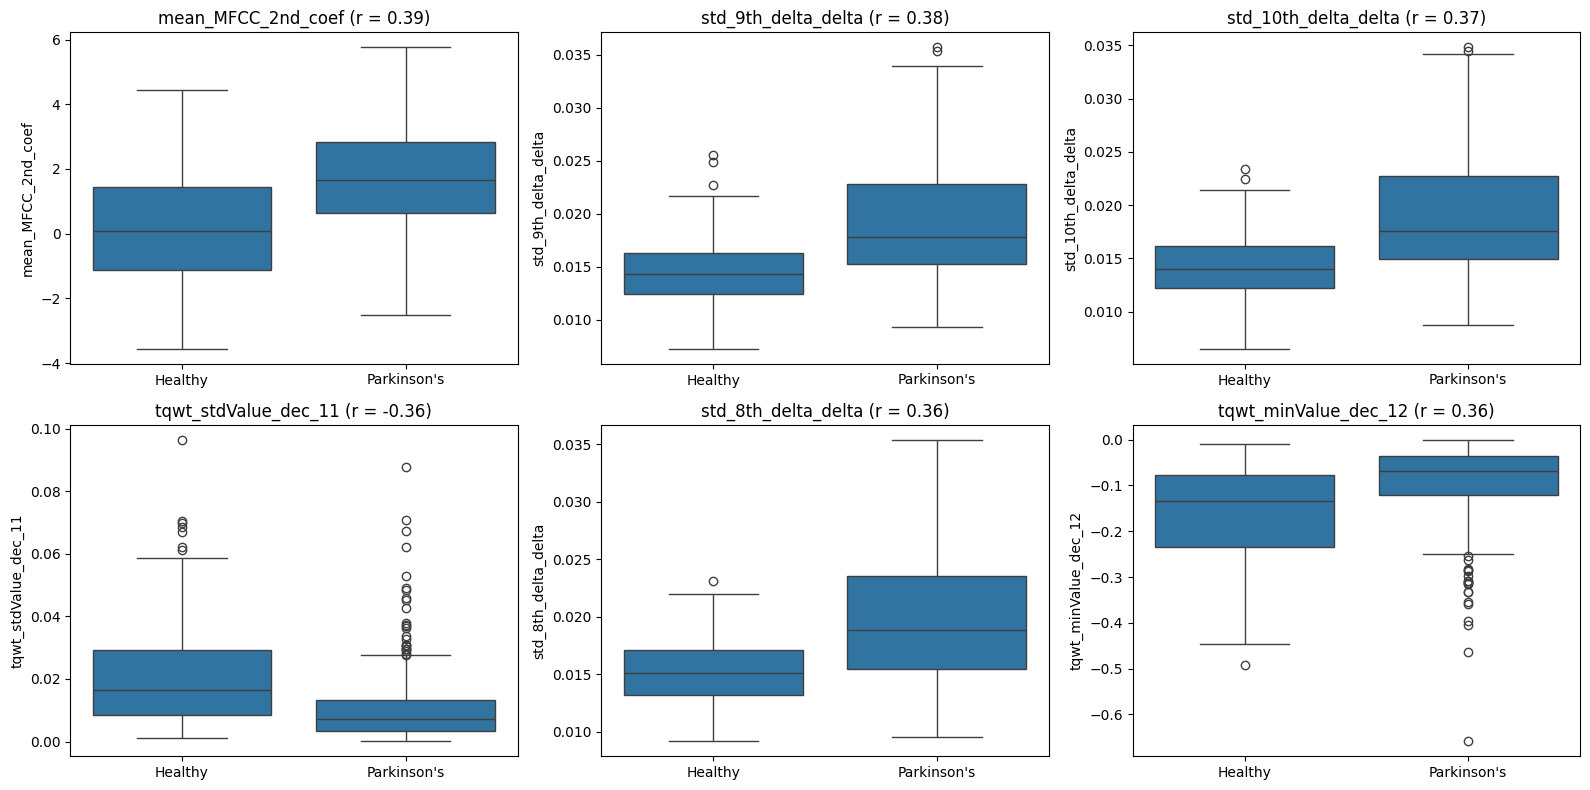

In [16]:
# 3. Boxplots of the top 6 features by class
top6 = target_corr.head(6).index
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), top6):
    sns.boxplot(x="class", y=col, data=train_df, ax=ax)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Healthy", "Parkinson's"])
    ax.set_title(f"{col} (r = {target_corr[col]:.2f})"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

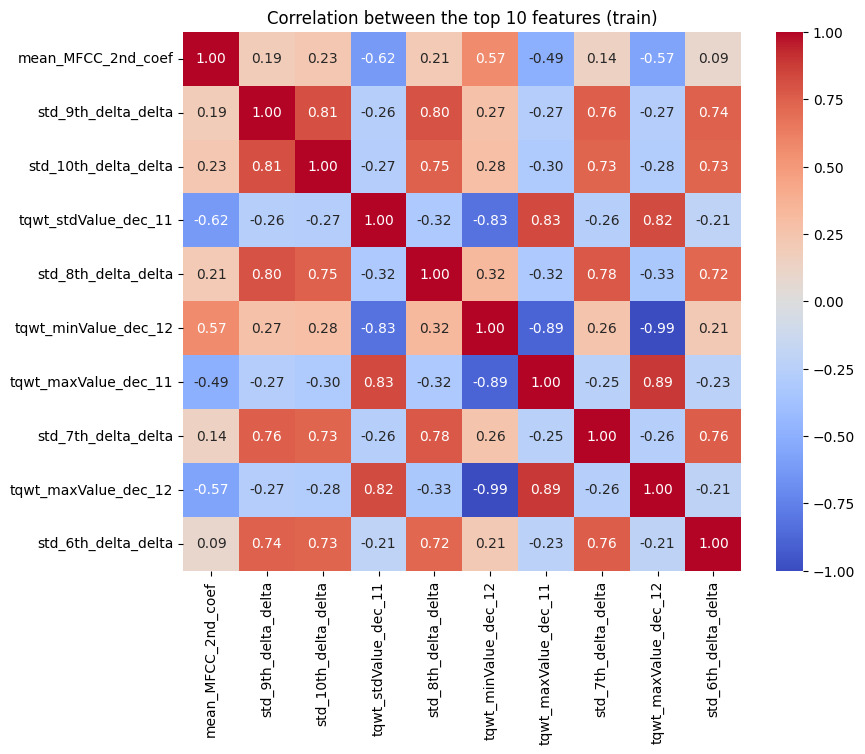

In [17]:
# 4. Heatmap of the top 10 features
plt.figure(figsize=(9, 7))
sns.heatmap(X_train[target_corr.head(10).index].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between the top 10 features (train)"); plt.show()

### Interpretation: EDA Part 2 – Correlations and Key Features

Multicollinearity:
There are 1,917 feature pairs with a correlation above 0.9, and 368 of the 753 features have at least one highly correlated "twin". Many features measure the same voice property in slightly different ways. For example, std_9th_delta_delta and std_10th_delta_delta have a correlation of 0.81, and tqwt_minValue_dec_12 and tqwt_maxValue_dec_12 have a correlation of -0.99. I will not remove these features, because SVM's regularization (the C parameter) handles correlated features well. But it shows the data has a lot of redundant information.

Features most related to the target:
The strongest correlation with class is only 0.387 (mean_MFCC_2nd_coef), and the top 10 features are all between 0.357 and 0.387 in absolute value. No single feature can separate healthy people from Parkinson's patients on its own, so the model needs to combine many weak signals. That is a good fit for SVM.

Boxplots:
- Parkinson's patients have higher values of mean_MFCC_2nd_coef and of the std_delta_delta features (6th to 10th). These delta-delta features measure how quickly the voice changes over time, so higher values suggest a less stable voice.
- Parkinson's patients have lower values of tqwt_stdValue_dec_11, and higher (closer to zero) values of tqwt_minValue_dec_12.
- In every plot the boxes are shifted between the two groups but still overlap. This confirms that each feature separates the classes only partly.

Heatmap:
The top 10 features form about three groups: the std_delta_delta features (correlations of 0.72 to 0.81 with each other), the TQWT decomposition features (correlations of 0.82 to 0.99 in absolute value), and mean_MFCC_2nd_coef, which is more independent. So the top 10 features really carry only a few distinct signals.

## Step 6: Data Cleaning – Missing Values and Near-Constant Features

In [18]:
# 1. Missing values (train and test)
print("Missing values - train:", X_train.isnull().sum().sum(), "| test:", X_test.isnull().sum().sum())


Missing values - train: 0 | test: 0


In [19]:
# 2. Near-constant features: learned from TRAINING data only
train_std = X_train.std()
near_constant = train_std[train_std < 1e-10].index.tolist()
print(f"\nNear-constant features (std < 1e-10): {len(near_constant)}")
print(near_constant)


Near-constant features (std < 1e-10): 35
['tqwt_meanValue_dec_1', 'tqwt_meanValue_dec_2', 'tqwt_meanValue_dec_3', 'tqwt_meanValue_dec_4', 'tqwt_meanValue_dec_5', 'tqwt_meanValue_dec_6', 'tqwt_meanValue_dec_7', 'tqwt_meanValue_dec_8', 'tqwt_meanValue_dec_9', 'tqwt_meanValue_dec_10', 'tqwt_meanValue_dec_11', 'tqwt_meanValue_dec_12', 'tqwt_meanValue_dec_13', 'tqwt_meanValue_dec_14', 'tqwt_meanValue_dec_15', 'tqwt_meanValue_dec_16', 'tqwt_meanValue_dec_17', 'tqwt_meanValue_dec_18', 'tqwt_meanValue_dec_19', 'tqwt_meanValue_dec_20', 'tqwt_meanValue_dec_21', 'tqwt_meanValue_dec_22', 'tqwt_meanValue_dec_23', 'tqwt_meanValue_dec_24', 'tqwt_meanValue_dec_25', 'tqwt_meanValue_dec_26', 'tqwt_meanValue_dec_27', 'tqwt_meanValue_dec_28', 'tqwt_meanValue_dec_29', 'tqwt_meanValue_dec_30', 'tqwt_meanValue_dec_31', 'tqwt_meanValue_dec_32', 'tqwt_meanValue_dec_33', 'tqwt_meanValue_dec_34', 'tqwt_meanValue_dec_35']


In [20]:
# 3. Drop them from both sets
X_train_c = X_train.drop(columns=near_constant)
X_test_c = X_test.drop(columns=near_constant)

print("\nShape after cleaning - train:", X_train_c.shape, "| test:", X_test_c.shape)
print("Smallest std remaining:", X_train_c.std().min())
print("Same columns in train and test:", list(X_train_c.columns) == list(X_test_c.columns))


Shape after cleaning - train: (602, 718) | test: (153, 718)
Smallest std remaining: 2.798692201762199e-06
Same columns in train and test: True


### Interpretation: Data Cleaning

Missing values:
There are no missing values in the training or the test set, so no imputation is needed.

Near-constant features:
I removed features with a standard deviation below 0.0000000001 (10 to the power of -10), using the training data only. This removed 35 features: tqwt_meanValue_dec_1 to tqwt_meanValue_dec_35, the whole "mean value" group of the TQWT features. Their values are practically zero for every recording, so they carry no useful information. If I kept them, StandardScaler would divide this tiny noise by its tiny standard deviation and make it as large as the real features, which could confuse the SVM.

After cleaning, there are 718 features. The smallest remaining standard deviation is about 0.0000028, which matches the gap I saw in the histogram in Step 4. The training and test sets have exactly the same columns.

I kept the highly correlated features, because SVM's regularization can handle them.

## Step 7: Build and Train Baseline SVM Models – Linear vs RBF Kernel

=== SVM Linear (default) ===
              precision    recall  f1-score   support

     Healthy       0.53      0.46      0.49        39
 Parkinson's       0.82      0.86      0.84       114

    accuracy                           0.76       153
   macro avg       0.68      0.66      0.67       153
weighted avg       0.75      0.76      0.75       153



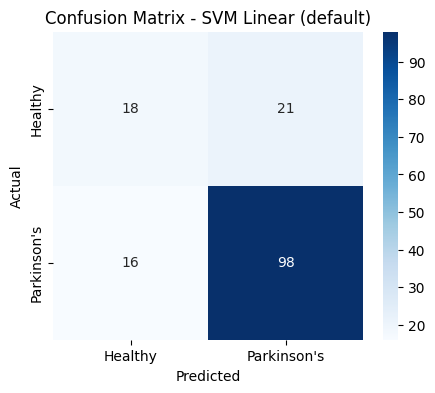

=== SVM RBF (default) ===
              precision    recall  f1-score   support

     Healthy       1.00      0.44      0.61        39
 Parkinson's       0.84      1.00      0.91       114

    accuracy                           0.86       153
   macro avg       0.92      0.72      0.76       153
weighted avg       0.88      0.86      0.83       153



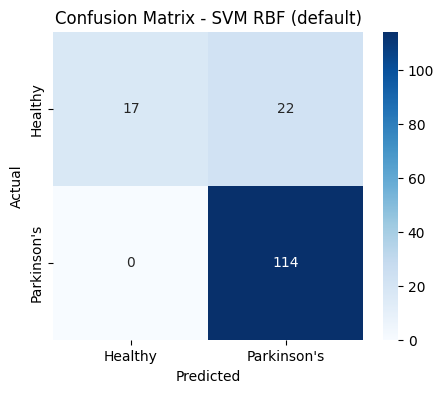

In [21]:
from sklearn.metrics import make_scorer

def evaluate(name, model):
    train_pred = model.predict(X_train_c)
    pred = model.predict(X_test_c)
    scores = model.decision_function(X_test_c)
    result = {"Model": name,
              "Train acc": accuracy_score(y_train, train_pred),
              "Test acc": accuracy_score(y_test, pred),
              "Recall healthy": recall_score(y_test, pred, pos_label=0),
              "Recall PD": recall_score(y_test, pred, pos_label=1),
              "Macro F1": f1_score(y_test, pred, average="macro"),
              "ROC-AUC": roc_auc_score(y_test, scores)}
    print(f"=== {name} ===")
    print(classification_report(y_test, pred, target_names=["Healthy", "Parkinson's"]))
    cm = confusion_matrix(y_test, pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Healthy", "Parkinson's"], yticklabels=["Healthy", "Parkinson's"])
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"Confusion Matrix - {name}")
    plt.show()
    return result

results = []

svm_linear = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="linear", random_state=42))])
svm_linear.fit(X_train_c, y_train)
results.append(evaluate("SVM Linear (default)", svm_linear))

svm_rbf = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="rbf", random_state=42))])
svm_rbf.fit(X_train_c, y_train)
results.append(evaluate("SVM RBF (default)", svm_rbf))

In [22]:
# 5-fold cross-validation on training data, split by person
cv_group = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"accuracy": "accuracy", "macro_f1": "f1_macro", "roc_auc": "roc_auc",
           "recall_healthy": make_scorer(recall_score, pos_label=0)}
cv_rows = []
for name, model in [("SVM Linear (default)", svm_linear), ("SVM RBF (default)", svm_rbf)]:
    cv = cross_validate(model, X_train_c, y_train, groups=groups_train, cv=cv_group, scoring=scoring)
    cv_rows.append({"Model": name, **{m: round(cv[f"test_{m}"].mean(), 3) for m in scoring},
                    "macro_f1 (std)": round(cv["test_macro_f1"].std(), 3)})
print("5-fold CV (training data, grouped by person):")
print(pd.DataFrame(cv_rows).to_string(index=False))

print("\nTest set summary:")
print(pd.DataFrame(results).round(3).to_string(index=False))

5-fold CV (training data, grouped by person):
               Model  accuracy  macro_f1  roc_auc  recall_healthy  macro_f1 (std)
SVM Linear (default)     0.745     0.662    0.735           0.516           0.108
   SVM RBF (default)     0.816     0.693    0.790           0.368           0.052

Test set summary:
               Model  Train acc  Test acc  Recall healthy  Recall PD  Macro F1  ROC-AUC
SVM Linear (default)      1.000     0.758           0.462       0.86     0.667    0.762
   SVM RBF (default)      0.907     0.856           0.436       1.00     0.760    0.919


### Interpretation: Baseline SVM Models (Linear vs RBF)

Linear kernel:
The linear SVM reached 100% training accuracy but only 75.8% test accuracy, which shows strong overfitting. With 718 features and only 602 training recordings, a straight hyperplane can always separate the training data perfectly, but it does not generalize well to new people. It caught 98 of 114 Parkinson's patients (recall 0.86), but only 18 of 39 healthy people (recall 0.46). Its cross-validation macro F1 was 0.662, with a large standard deviation of 0.108, so its performance changes a lot depending on which people are in the fold.

RBF kernel:
The RBF SVM performed better: 90.7% training accuracy and 85.6% test accuracy, so it overfits much less. It correctly identified all 114 Parkinson's patients (recall 1.00), and when it predicted "healthy" it was always right (precision 1.00 for the healthy class). However, it identified only 17 of 39 healthy people (recall 0.44) and labelled the other 22 as Parkinson's. The model is biased towards the majority class because the data is imbalanced (75% Parkinson's).

Cross-validation vs test:
For the RBF model, the cross-validation results (accuracy 0.816, macro F1 0.693, ROC-AUC 0.790, healthy recall 0.368) are lower than the test results (accuracy 0.856, macro F1 0.760, ROC-AUC 0.919). The test set has only 51 people, so it may simply be an easier group. I trust the cross-validation results more, because they average over 5 different groups of people.

Overall, RBF is the better default model, but both models struggle to recognize healthy people. In the next step I will tune C, gamma and class_weight to improve this.

## Step 8: Hyperparameter Tuning with GridSearchCV

In [23]:
param_grid = [
    {"svm__kernel": ["linear"],
     "svm__C": [0.0001, 0.001, 0.01, 0.1, 1],
     "svm__class_weight": [None, "balanced"]},
    {"svm__kernel": ["rbf"],
     "svm__C": [0.1, 1, 10, 100],
     "svm__gamma": ["scale", 0.00001, 0.00005, 0.0001, 0.0005, 0.001, 0.005],
     "svm__class_weight": [None, "balanced"]}
]

svm_pipe = Pipeline([("scaler", StandardScaler()), ("svm", SVC(random_state=42))])

grid = GridSearchCV(svm_pipe, param_grid, scoring="f1_macro", cv=cv_group,
                    n_jobs=-1, return_train_score=True)
grid.fit(X_train_c, y_train, groups=groups_train)

print("Best parameters:", grid.best_params_)
print("Best CV macro F1:", round(grid.best_score_, 3))
print("Train macro F1 (CV):", round(grid.cv_results_["mean_train_score"][grid.best_index_], 3))




Best parameters: {'svm__C': 100, 'svm__class_weight': None, 'svm__gamma': 1e-05, 'svm__kernel': 'rbf'}
Best CV macro F1: 0.743
Train macro F1 (CV): 0.849


In [24]:
cv_res = pd.DataFrame(grid.cv_results_)
cols = ["param_svm__kernel", "param_svm__C", "param_svm__gamma", "param_svm__class_weight",
        "mean_train_score", "mean_test_score", "std_test_score"]
print("\nTop 8 combinations:")
print(cv_res.sort_values("rank_test_score")[cols].head(8).round(3).to_string(index=False))




Top 8 combinations:
param_svm__kernel  param_svm__C param_svm__gamma param_svm__class_weight  mean_train_score  mean_test_score  std_test_score
              rbf       100.000          0.00001                     NaN             0.849            0.743           0.079
              rbf        10.000           0.0001                     NaN             0.851            0.734           0.074
           linear         0.001              NaN                     NaN             0.804            0.731           0.078
              rbf        10.000          0.00005                     NaN             0.804            0.729           0.076
              rbf        10.000           0.0005                     NaN             0.988            0.719           0.086
              rbf       100.000          0.00005                balanced             0.970            0.717           0.097
              rbf       100.000          0.00005                     NaN             0.963            0.714    


Best linear: C=0.001, gamma=nan, class_weight=nan -> CV macro F1 0.731

Best rbf: C=100.0, gamma=1e-05, class_weight=nan -> CV macro F1 0.743
=== SVM (tuned) ===
              precision    recall  f1-score   support

     Healthy       0.93      0.64      0.76        39
 Parkinson's       0.89      0.98      0.93       114

    accuracy                           0.90       153
   macro avg       0.91      0.81      0.85       153
weighted avg       0.90      0.90      0.89       153



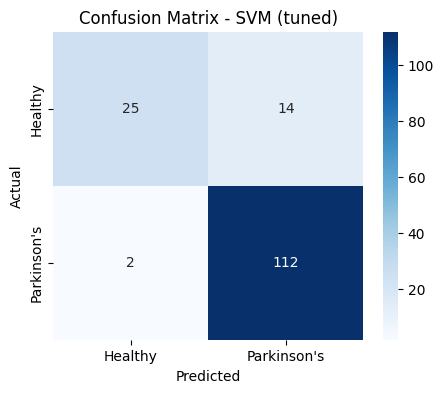

In [25]:
# Best linear vs best RBF
for k in ["linear", "rbf"]:
    best_k = cv_res[cv_res["param_svm__kernel"] == k].sort_values("rank_test_score").iloc[0]
    print(f"\nBest {k}: C={best_k['param_svm__C']}, gamma={best_k['param_svm__gamma']}, "
          f"class_weight={best_k['param_svm__class_weight']} -> CV macro F1 {best_k['mean_test_score']:.3f}")

svm_best = grid.best_estimator_
results.append(evaluate("SVM (tuned)", svm_best))

### Interpretation: Hyperparameter Tuning with GridSearchCV

I tested 66 combinations (10 linear and 56 RBF) with 5-fold cross-validation, grouped by person, and chose the best by macro F1 (the average F1 of both classes). In the results table, NaN means the setting was None: no class weight, or no gamma for the linear kernel.

Best model:
The best model was an RBF kernel with C = 100, gamma = 0.00001 and no class weight. Its CV macro F1 was 0.743, up from 0.693 for the default RBF model. The very small gamma makes the boundary very smooth, close to a straight line, while the large C makes the model strict about mistakes. Together they balance each other.

Linear vs RBF:
The best linear model (C = 0.001) reached a CV macro F1 of 0.731, very close to the best RBF (0.743). The difference is smaller than the standard deviation between folds (about 0.08), so both kernels perform similarly once tuned. The linear kernel only worked well with a very small C (strong regularization), which confirms that the default linear model (C = 1) was overfitting.

Class weight:
Surprisingly, class_weight = "balanced" did not improve the results. Its best combination scored 0.717, and the balanced models had higher variation between folds.

Overfitting:
The training macro F1 of the best model is 0.849 and the CV macro F1 is 0.743. There is still some overfitting, but much less than the default linear model, which had 100% training accuracy.

Test set:
- Accuracy improved from 85.6% (default RBF) to 90%.
- Healthy recall improved from 0.44 to 0.64: the model now correctly identifies 25 of 39 healthy people instead of 17.
- Parkinson's recall is 0.98: 112 of 114 patients were caught, and only 2 were missed.
- Macro F1 improved from 0.76 to 0.85.
- When the model predicts "healthy", it is right 93% of the time.

## Step 9: Final Comparison of SVM Models

In [26]:
# Test set comparison
final_df = pd.DataFrame(results).round(3)
print("Test set results:")
print(final_df.to_string(index=False))



Test set results:
               Model  Train acc  Test acc  Recall healthy  Recall PD  Macro F1  ROC-AUC
SVM Linear (default)      1.000     0.758           0.462      0.860     0.667    0.762
   SVM RBF (default)      0.907     0.856           0.436      1.000     0.760    0.919
         SVM (tuned)      0.897     0.895           0.641      0.982     0.845    0.886


In [27]:
# Cross-validated macro F1 comparison
best_lin = cv_res[cv_res["param_svm__kernel"] == "linear"]["mean_test_score"].max()
cv_compare = pd.DataFrame({
    "Model": ["SVM Linear (default)", "SVM RBF (default)", "SVM Linear (tuned)", "SVM RBF (tuned)"],
    "CV macro F1": [cv_rows[0]["macro_f1"], cv_rows[1]["macro_f1"], round(best_lin, 3), round(grid.best_score_, 3)]
})
print("\n5-fold CV macro F1 (grouped by person):")
print(cv_compare.to_string(index=False))



5-fold CV macro F1 (grouped by person):
               Model  CV macro F1
SVM Linear (default)        0.662
   SVM RBF (default)        0.693
  SVM Linear (tuned)        0.731
     SVM RBF (tuned)        0.743


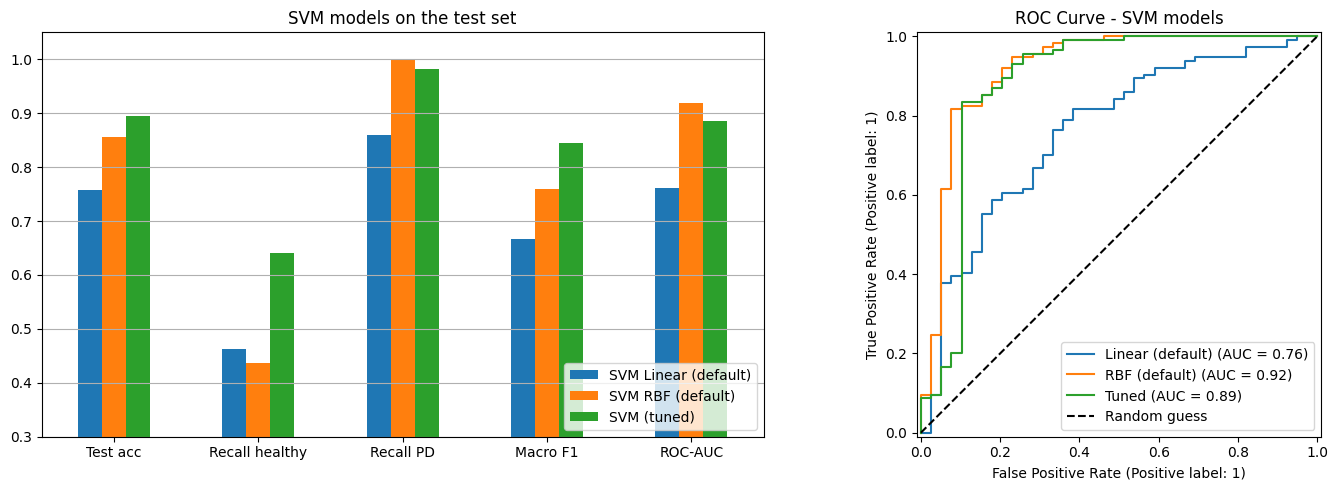

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Bar chart of test metrics
final_df.set_index("Model")[["Test acc", "Recall healthy", "Recall PD", "Macro F1", "ROC-AUC"]].T.plot(
    kind="bar", ax=axes[0], rot=0)
axes[0].set_ylim(0.3, 1.05); axes[0].set_title("SVM models on the test set")
axes[0].legend(loc="lower right"); axes[0].grid(axis="y")

# ROC curves
for name, model in [("Linear (default)", svm_linear), ("RBF (default)", svm_rbf), ("Tuned", svm_best)]:
    RocCurveDisplay.from_estimator(model, X_test_c, y_test, name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess"); axes[1].legend()
axes[1].set_title("ROC Curve - SVM models")
plt.tight_layout(); plt.show()

### Interpretation: Final Comparison of SVM Models

Cross-validation:
The cross-validated macro F1, grouped by person, improved step by step: 0.662 for the default linear model, 0.693 for the default RBF, 0.731 for the tuned linear model and 0.743 for the tuned RBF. Tuning improved both kernels, and the linear kernel improved the most (+0.069), because a very small C fixed its overfitting. After tuning, the two kernels are close, with RBF slightly ahead.

Test set:
The tuned RBF model gave the best predictions on the test set: 89.5% accuracy, 0.641 healthy recall, 0.982 Parkinson's recall and 0.845 macro F1. The biggest improvement is in recognizing healthy people (from about 0.44 to 0.64). The training accuracy (89.7%) is almost the same as the test accuracy (89.5%), so the tuned model generalizes well to new people.

ROC-AUC:
The tuned model's ROC-AUC (0.886) is lower than the default RBF's (0.919). ROC-AUC measures how well the model ranks patients across all possible thresholds, while accuracy, recall and F1 are measured at the model's actual decision point. The default RBF ranks well, but its decision point labels most healthy people as Parkinson's. The tuned model makes better actual predictions. The test set has only 51 people, so the ROC curves are step-shaped and a few people can change the AUC. I rely more on the cross-validation results and the actual prediction metrics.

The default linear model is clearly the weakest: its ROC curve is much lower (AUC 0.762), and it overfits badly (100% training accuracy).

## Step 10: Report – SVM on the Parkinson's Disease Dataset

### Overview
I built a Support Vector Machine (SVM) classifier to predict Parkinson's disease from voice recordings. The dataset has 756 recordings from 252 people (3 per person) and 753 voice features. About 75% of the recordings are from Parkinson's patients and 25% from healthy people. After removing 1 duplicate and 35 near-constant features, I trained the models on 718 scaled features. I split the data by person (80/20) and used 5-fold cross-validation grouped by person.

### Model performance

| Model | CV macro F1 | Test accuracy | Healthy recall | Parkinson's recall | Test macro F1 | ROC-AUC |
|---|---|---|---|---|---|---|
| SVM Linear (default) | 0.662 | 0.758 | 0.462 | 0.860 | 0.667 | 0.762 |
| SVM RBF (default) | 0.693 | 0.856 | 0.436 | 1.000 | 0.760 | 0.919 |
| SVM Linear (tuned, C=0.001) | 0.731 | – | – | – | – | – |
| **SVM RBF (tuned, C=100, gamma=0.00001)** | **0.743** | **0.895** | **0.641** | **0.982** | **0.845** | 0.886 |

### How well did the SVM model perform?
The tuned RBF SVM performed well. It correctly classified 89.5% of recordings from people it had never seen before, and it caught 112 of 114 Parkinson's patients (recall 0.98). When it predicted "healthy", it was right 93% of the time. Its main weakness is recognizing healthy people: it identified 25 of 39 (recall 0.64), and labelled the other 14 as Parkinson's. In a medical screening setting, this is the safer kind of mistake, because a false alarm leads to a follow-up test, while a missed patient goes untreated. Still, there is room to improve.

Tuning made a clear difference. The cross-validated macro F1 rose from 0.693 to 0.743, healthy recall rose from 0.44 to 0.64, and overfitting dropped (training and test accuracy are now almost equal, 89.7% vs 89.5%). The RBF kernel with a very small gamma (a very smooth boundary) and a large C worked best. A strongly regularized linear kernel was almost as good (CV macro F1 0.731).

### Challenges faced
1. **Repeated recordings (data leakage):** each person was recorded 3 times. A random split would put the same person in both the training and test sets, and the model could "recognize" voices instead of learning signs of Parkinson's. I used StratifiedGroupKFold to split by person, for both the train/test split and cross-validation.
2. **High dimensionality:** there were 753 features but only 252 people. The default linear SVM reached 100% training accuracy and only 75.8% test accuracy. Strong regularization (a small C for linear, a small gamma for RBF) was needed.
3. **Very different feature scales:** standard deviations ranged from about 10^-21 to 10^9. Scaling was essential for SVM, so I used StandardScaler inside a Pipeline so it was learned from the training data only.
4. **Near-constant noise features:** 35 TQWT mean-value features were practically zero. Standardizing them would have blown noise up to the size of the real features, so I removed them.
5. **Class imbalance (75/25):** the default models leaned towards predicting Parkinson's (the default RBF caught only 17 of 39 healthy people). I used macro F1 to treat both classes equally. class_weight = "balanced" did not help in cross-validation.
6. **Small test set:** the test set has only 51 people, so the results can change a lot with a few people. For example, the tuned model has a lower test ROC-AUC (0.886) than the default RBF (0.919) despite better predictions. I relied mainly on grouped cross-validation.
7. **Skewed features:** 541 features were strongly skewed, and many contained negative values, so a log transform was not possible. I relied on standardization.

### Possible improvements
- Extend the grid search: the best gamma (0.00001) and C (100) were at the edges of my grid.
- Reduce dimensionality (for example with PCA or feature selection) before the SVM.
- Tune the decision threshold to improve healthy recall.
- Combine each person's 3 recordings into one prediction (for example, a majority vote).